# Pneumonia Detection from Chest X-Rays — Baseline CNN vs. Transfer Learning

**Course:** Neural Networks and Deep Learning
**Task:** Binary classification (NORMAL vs. PNEUMONIA) of chest X-rays from the Kaggle
*Chest X-Ray Images (Pneumonia)* dataset (Kermany et al.), used from a locally downloaded copy.
The program implements a **normal CNN trained from scratch** and two **pretrained transfer-learning
models**, then compares how their results differ.

The classification arms, all trained through the same data pipeline, loss and optimiser:

| # | Model | Pretrained weights | Trainable parameters |
|---|-------|--------------------|----------------------|
| 1 | Baseline CNN — four conv blocks, from scratch | none | ~1.2M |
| 2 | ConvNeXt-Tiny + custom head | ImageNet (early stages frozen) | ~15.6M |
| 3 | EfficientNet-B0 + custom head | ImageNet (early blocks frozen) | ~1.3M |

Soft-voting ensembles of these models are then evaluated as a fourth and fifth arm. Because data
loading, the patient-level split, augmentation, loss, optimiser and evaluation are shared, differences
in the results come from the architectures and from the presence or absence of pretrained weights.

## 1. Setup — dataset download (no API key needed)

This notebook uses a locally downloaded copy of the dataset — no Kaggle API key required.

**Download it manually:**
1. Go to the dataset page: **https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia**
2. Sign in to Kaggle (free account) if prompted.
3. Click the **Download** button (top-right of the page) — this downloads `archive.zip`
   (sometimes named `chest-xray-pneumonia.zip`), about 1.2 GB.
4. Place the downloaded zip file in the **same folder as this notebook**.
5. Run the extraction cell below — it will unzip it into `data/` and locate the `train/` and `test/`
   folders automatically, whether the zip contains them directly or nests them one level deeper
   (both layouts are common for this particular dataset).

> Mirror: the same dataset is also mirrored at
> **https://data.mendeley.com/datasets/rscbjbr9sj/3** if the Kaggle page is ever unavailable.

> The first time the pretrained models are created, PyTorch downloads the ImageNet weights (about
> 110 MB for ConvNeXt-Tiny and 21 MB for EfficientNet-B0), so the computer needs an internet
> connection for that one step. The baseline CNN needs no download.

In [9]:
# Core / deep-learning imports
import os
import re
import time
import copy
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
    cohen_kappa_score,
)
from scipy.stats import binomtest

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Deterministic cuDNN and re-seeded data-loader workers, so a second run reproduces these numbers.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True


def seed_worker(worker_id):
    # Worker processes inherit the parent RNG state, which would make the random augmentations
    # identical inside every worker. Re-seeding from torch's per-worker base seed fixes that.
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


In [10]:
# Locate a manually downloaded zip next to the notebook (handles either common filename)
ZIP_CANDIDATES = ["chest-xray-pneumonia.zip", "archive.zip"]
ZIP_PATH = next((Path(p) for p in ZIP_CANDIDATES if Path(p).exists()), None)

DATA_ROOT = Path("data")


def find_dataset_root(base):
    # Return the folder that holds train/ and test/ (each with NORMAL/ and PNEUMONIA/), or None.
    # The shallowest match wins, so a duplicated nested copy of the dataset is never picked by mistake.
    base = Path(base)
    if not base.exists():
        return None
    matches = [c.parent for c in base.rglob("train")
               if c.is_dir() and (c / "NORMAL").is_dir() and (c.parent / "test").is_dir()
               and "__MACOSX" not in c.parts]
    return min(matches, key=lambda p: (len(p.parts), str(p))) if matches else None


DATA_DIR = find_dataset_root(DATA_ROOT)

if DATA_DIR is None:
    if ZIP_PATH is None:
        raise FileNotFoundError(
            "Could not find archive.zip / chest-xray-pneumonia.zip next to this notebook.\n"
            "Download it from https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia "
            "and place the zip in this notebook's folder, then re-run this cell."
        )
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_ROOT)
    print(f"Extracted {ZIP_PATH} -> {DATA_ROOT}/")
    DATA_DIR = find_dataset_root(DATA_ROOT)
else:
    print("Dataset already extracted.")

assert DATA_DIR is not None and (DATA_DIR / "train").exists() and (DATA_DIR / "test").exists(), \
    "Expected train/ and test/ folders under data/ - check the extracted layout."
print("Dataset root:", DATA_DIR.resolve())

# Park any stray sub-folder (e.g. a leftover train/train from an earlier extraction attempt) outside the
# dataset, so ImageFolder never mistakes it for a third class. Nothing is deleted - it is only moved.
UNUSED_DIR = DATA_ROOT / "_unused_nested_copies"
for split in ["train", "test", "val"]:
    split_dir = DATA_DIR / split
    if not split_dir.is_dir():
        continue
    for item in sorted(split_dir.iterdir()):
        if item.is_dir() and item.name not in ("NORMAL", "PNEUMONIA"):
            UNUSED_DIR.mkdir(parents=True, exist_ok=True)
            target, k = UNUSED_DIR / f"{split}_{item.name}", 1
            while target.exists():
                target, k = UNUSED_DIR / f"{split}_{item.name}_{k}", k + 1
            shutil.move(str(item), str(target))
            print(f"Moved stray folder {item} -> {target}")

Extracted archive.zip -> data/
Dataset root: /home/pranam/Pytorch/data/chest_xray


## 2. Dataset overview

The dataset ships with its own `train` / `val` / `test` split, each containing `NORMAL/` and
`PNEUMONIA/` subfolders of JPEG X-rays. The provided `val` split is tiny (16 images), so we
re-derive a proper validation split from the training data — **grouped by patient**, so that no patient
appears on both sides — and keep the original `test` folder untouched as the held-out test set.

In [13]:
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

for cls in ["NORMAL", "PNEUMONIA"]:
    n_train = len(list((TRAIN_DIR / cls).glob("*.jpeg")))
    n_test = len(list((TEST_DIR / cls).glob("*.jpeg")))
    print(f"{cls:10s} | train: {n_train:5d} | test: {n_test:5d}")

NORMAL     | train:  1341 | test:   234
PNEUMONIA  | train:  3875 | test:   390


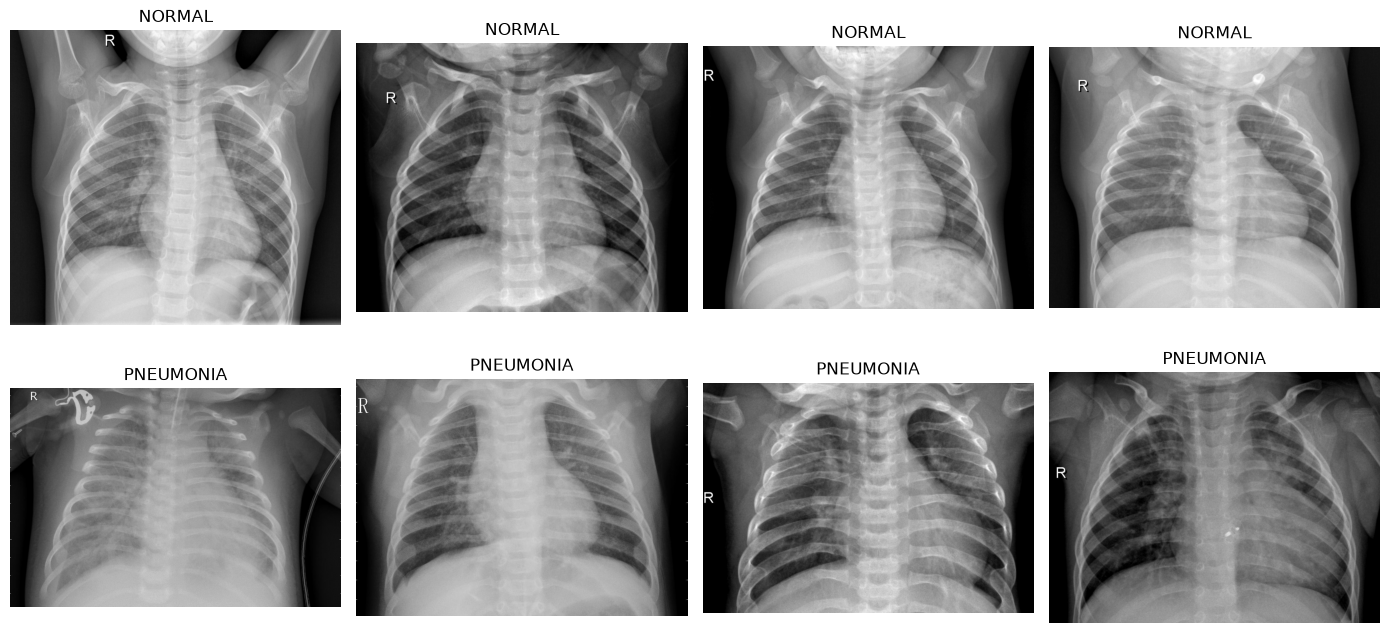

In [14]:
# Peek at a few sample images from each class
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, cls in enumerate(["NORMAL", "PNEUMONIA"]):
    sample_files = sorted((TRAIN_DIR / cls).glob("*.jpeg"))[:4]
    for col, fpath in enumerate(sample_files):
        img = plt.imread(fpath)
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 3. Data loading, splitting, and augmentation

- Images are resized to 224x224 and converted to 3-channel tensors (needed for the pretrained
  backbones; the baseline CNN uses the same input so the comparison is apples-to-apples).
- Light augmentation (random flip, small rotation) is applied to the training split only.
- Normalisation uses ImageNet mean/std for all models, so the same pipeline works everywhere.
- Only images that sit **directly** inside `train/NORMAL`, `train/PNEUMONIA` (and the same for `test`)
  are loaded, which keeps the counts correct even if a zip extraction left a nested duplicate behind.
- The train/validation split is **grouped by patient**. The dataset contains several images per child and
  the filename encodes the patient id, so a random image-level split would leak the same patient into both
  sides and inflate validation accuracy. `StratifiedGroupKFold` keeps the class balance while never
  splitting a patient across the two sets.
- The training set is 74% PNEUMONIA, so a `WeightedRandomSampler` draws balanced batches; the loss itself
  stays unweighted and every metric below is computed on the natural test distribution.

In [15]:
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.3),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

IMG_EXTS = {".jpeg", ".jpg", ".png"}


def top_level_images_only(root):
    # is_valid_file for ImageFolder: accept only <root>/<CLASS>/<image>, ignore anything nested deeper
    root = os.path.normpath(str(root))
    def _valid(path):
        p = Path(path)
        return (p.suffix.lower() in IMG_EXTS and not p.name.startswith(".")
                and os.path.normpath(str(p.parent.parent)) == root)
    return _valid


full_train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform,
                                          is_valid_file=top_level_images_only(TRAIN_DIR))
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform,
                                    is_valid_file=top_level_images_only(TEST_DIR))

print("Classes:", full_train_dataset.classes)  # ['NORMAL', 'PNEUMONIA']

Classes: ['NORMAL', 'PNEUMONIA']


In [16]:
from sklearn.model_selection import StratifiedGroupKFold

# Filenames encode the patient: person137_bacteria_650.jpeg, NORMAL2-IM-0382-0001.jpeg.
def patient_id(path):
    name = Path(path).name
    match = re.match(r"(person\d+)", name)
    if match:
        return match.group(1)
    match = re.match(r"((?:NORMAL2-)?IM-\d+)", name)
    if match:
        return match.group(1)
    return Path(path).stem


targets = np.array(full_train_dataset.targets)
paths = [p for p, _ in full_train_dataset.samples]
groups = np.array([patient_id(p) for p in paths])
print(f"{len(paths)} images from {len(np.unique(groups))} patients in the official train folder")

# n_splits=7 holds out roughly 14% of the patients as validation, stratified by class.
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf.split(np.zeros(len(paths)), targets, groups))

# Validation subset must use the non-augmented transform
val_dataset_raw = datasets.ImageFolder(TRAIN_DIR, transform=eval_transform,
                                      is_valid_file=top_level_images_only(TRAIN_DIR))
assert full_train_dataset.samples == val_dataset_raw.samples, \
    "the two ImageFolders scanned the folder differently, so index positions would not line up"

train_subset = torch.utils.data.Subset(full_train_dataset, train_idx)
val_subset = torch.utils.data.Subset(val_dataset_raw, val_idx)

print(f"Train: {len(train_subset)} | Val: {len(val_subset)} | Test: {len(test_dataset)}")

5216 images from 2846 patients in the official train folder
Train: 4470 | Val: 746 | Test: 624


In [17]:
# Sanity checks: class mapping, no duplicated files, and no patient on both sides of the split.
print(full_train_dataset.classes)
print(full_train_dataset.class_to_idx)
print(np.unique(targets))

all_paths = [p for p, _ in full_train_dataset.samples]
assert len(all_paths) == len(set(all_paths)), "Duplicate image paths found in the training set!"
assert len(set(os.path.basename(p) for p in all_paths)) == len(all_paths), \
    "Duplicate file names found - the dataset folder may contain a duplicated copy of the images."

for cls in ["NORMAL", "PNEUMONIA"]:
    n_files = len([f for f in (TRAIN_DIR / cls).iterdir()
                   if f.suffix.lower() in IMG_EXTS and not f.name.startswith(".")])
    n_loaded = int((targets == full_train_dataset.class_to_idx[cls]).sum())
    assert n_files == n_loaded, f"{cls}: {n_files} files on disk but {n_loaded} loaded"

train_patients = set(groups[train_idx])
val_patients = set(groups[val_idx])
assert train_patients.isdisjoint(val_patients), "A patient appears in both train and validation"

print(f"Loaded {len(full_train_dataset)} train+val images and {len(test_dataset)} test images "
      "(the standard Kaggle dataset has 5216 and 624).")
print(f"Patients - train: {len(train_patients)} | val: {len(val_patients)} | shared: 0")
print("Validation class counts:",
      {cls: int(n) for cls, n in zip(full_train_dataset.classes,
                                     np.bincount(targets[val_idx], minlength=2))})

['NORMAL', 'PNEUMONIA']
{'NORMAL': 0, 'PNEUMONIA': 1}
[0 1]
Loaded 5216 train+val images and 624 test images (the standard Kaggle dataset has 5216 and 624).
Patients - train: 2440 | val: 406 | shared: 0
Validation class counts: {'NORMAL': 192, 'PNEUMONIA': 554}


In [18]:
BATCH_SIZE = 32
NUM_WORKERS = 2

# Handle class imbalance (pneumonia is over-represented) with a weighted sampler, seeded for repeatability
class_counts = np.bincount(targets[train_idx])
class_weights = 1.0 / class_counts
sample_weights = class_weights[targets[train_idx]]
sampler = torch.utils.data.WeightedRandomSampler(
    weights=sample_weights, num_samples=len(sample_weights), replacement=True,
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, worker_init_fn=seed_worker)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, worker_init_fn=seed_worker)

print("Class counts (train):", dict(zip(full_train_dataset.classes, class_counts)))

Class counts (train): {'NORMAL': np.int64(1149), 'PNEUMONIA': np.int64(3321)}


## 4. Model 1 — Baseline CNN, trained from scratch

The control arm: a plain convolutional network with **no pretrained weights**. Four blocks, each with two
3x3 convolutions, BatchNorm, ReLU and 2x2 max-pooling (3 -> 32 -> 64 -> 128 -> 256 channels), followed by
global average pooling and a dropout head. About 1.2M parameters — comparable in size to the trainable part
of EfficientNet-B0 — so the comparison is mostly about *whether the features are pretrained*, not about
capacity.

In sampling terms this is the arm that answers the question: how well does ordinary CNN training do on
1,300 normal and 3,900 pneumonia films? Whatever it reaches, the gap to the transfer-learning arms is the
value those pretrained weights add. Since it cannot lean on pretrained features it is given more epochs
(`EPOCHS_BASELINE`) as well as a larger learning rate; loss, augmentation, sampler, split and evaluation are
otherwise identical.

In [19]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=2, drop=0.4):
        super().__init__()

        def block(channels_in, channels_out):
            return nn.Sequential(
                nn.Conv2d(channels_in, channels_out, 3, padding=1, bias=False),
                nn.BatchNorm2d(channels_out),
                nn.ReLU(inplace=True),
                nn.Conv2d(channels_out, channels_out, 3, padding=1, bias=False),
                nn.BatchNorm2d(channels_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            block(3, 32), block(32, 64), block(64, 128), block(128, 256),
        )
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(drop),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.global_pool(self.features(x)))


EPOCHS_BASELINE = 30   # from-scratch weights have no ImageNet features to start from

baseline_model = BaselineCNN(num_classes=2).to(DEVICE)
n_params_baseline = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
n_params_baseline_total = sum(p.numel() for p in baseline_model.parameters())
print(f"Baseline-CNN trainable parameters: {n_params_baseline:,} (of {n_params_baseline_total:,} total)")

Baseline-CNN trainable parameters: 1,206,370 (of 1,206,370 total)


## 5. Model 2 — ConvNeXt-Tiny (pretrained, custom head, partially fine-tuned)

ConvNeXt is a convolutional network modernised with ideas from Vision Transformers (large 7x7 depthwise
kernels, LayerNorm, GELU, inverted bottlenecks). It keeps the locality bias of CNNs, which suits medical
images, and uses LayerNorm instead of BatchNorm, so it does not depend on batch statistics.

Design used here:
- ImageNet-pretrained ConvNeXt-Tiny backbone (about 28M parameters).
- The early stages are **frozen** (generic edges and textures); only the **last stage** (stage 4) and a new
  head are trained. This adapts the high-level features to X-rays while keeping training fast and stable on
  a small dataset.
- New head: global average pooling -> LayerNorm -> Dropout -> Linear(768, 128) -> GELU -> Dropout -> Linear(128, 2).
- The frozen part is kept in evaluation mode while training so its statistics never change.

In [20]:
class ConvNeXtTinyCXR(nn.Module):
    def __init__(self, num_classes=2, drop=0.3):
        super().__init__()
        base = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        self.features = base.features              # [stem, stage1, down, stage2, down, stage3, down, stage4]
        self.unfreeze_from = 6                     # features[6:] = last downsample + stage 4 stay trainable
        for i, block in enumerate(self.features):
            for p in block.parameters():
                p.requires_grad = i >= self.unfreeze_from

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(768),
            nn.Dropout(drop),
            nn.Linear(768, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )

    def train(self, mode=True):
        super().train(mode)
        if mode:                                   # frozen blocks always stay in eval mode
            for block in self.features[:self.unfreeze_from]:
                block.eval()
        return self

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        return self.classifier(x)


convnext_model = ConvNeXtTinyCXR(num_classes=2).to(DEVICE)
n_params_convnext = sum(p.numel() for p in convnext_model.parameters() if p.requires_grad)
n_params_convnext_total = sum(p.numel() for p in convnext_model.parameters())
print(f"ConvNeXt-Tiny trainable parameters: {n_params_convnext:,} (of {n_params_convnext_total:,} total)")

ConvNeXt-Tiny trainable parameters: 15,570,818 (of 27,918,818 total)


## 6. Model 3 — EfficientNet-B0 (pretrained, custom head, partially fine-tuned)

EfficientNet-B0 is a compact network (about 5M parameters) built from MBConv blocks with
squeeze-and-excitation attention and BatchNorm. It is architecturally very different from ConvNeXt, which
makes it a useful second opinion for the ensemble.

It follows the same design as Model 2: frozen early blocks (kept in eval mode), the last two blocks
(`features[7:]`, including the final 1x1 convolution) trainable, and a new head
(global average pooling -> Dropout -> Linear(1280, 128) -> ReLU -> Dropout -> Linear(128, 2)).

In [21]:
class EfficientNetB0CXR(nn.Module):
    def __init__(self, num_classes=2, drop=0.3):
        super().__init__()
        base = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.features = base.features              # 9 blocks: features[0] ... features[8]
        self.unfreeze_from = 7                     # features[7:] stay trainable
        for i, block in enumerate(self.features):
            for p in block.parameters():
                p.requires_grad = i >= self.unfreeze_from

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(drop),
            nn.Linear(1280, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )

    def train(self, mode=True):
        super().train(mode)
        if mode:                                   # keeps frozen BatchNorm statistics untouched
            for block in self.features[:self.unfreeze_from]:
                block.eval()
        return self

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        return self.classifier(x)


effnet_model = EfficientNetB0CXR(num_classes=2).to(DEVICE)
n_params_effnet = sum(p.numel() for p in effnet_model.parameters() if p.requires_grad)
n_params_effnet_total = sum(p.numel() for p in effnet_model.parameters())
print(f"EfficientNet-B0 trainable parameters: {n_params_effnet:,} (of {n_params_effnet_total:,} total)")

EfficientNet-B0 trainable parameters: 1,293,618 (of 4,171,774 total)


## 7. Shared training and evaluation utilities

Every model uses the same loss (cross-entropy), optimiser family (Adam), batch size, augmentation and
evaluation code. The last checkpoint by validation loss is restored before the model is scored, so no
model is evaluated on an over-fitted final epoch.

Evaluation reports **ROC-AUC** (threshold-free) together with accuracy, precision, recall, specificity and
F1 at an explicit threshold. Because the models are trained on balanced batches but scored on a test set
that is 62% PNEUMONIA, a fixed 0.5 cut is not a neutral choice — a cut of 0.5 on a posterior shifted by the
sampler makes every model call far too many images pneumonia. Each model's threshold is therefore chosen on
the **validation split only** (maximising Youden's J) and then applied unchanged to the test set.

In [22]:
EPOCHS = 10


def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=1e-3, label="model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        start = time.time()

        # ---- Train ----
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # ---- Validate ----
        model.eval()
        val_running_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)
                preds = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        elapsed = time.time() - start
        print(f"[{label}] Epoch {epoch+1}/{epochs} "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} ({elapsed:.1f}s)")

    model.load_state_dict(best_state)
    return model, history

In [23]:
@torch.no_grad()
def probs_and_labels(model, data_loader):
    # P(PNEUMONIA) and the true labels for a whole loader, in loader order.
    model.eval()
    labels, probs = [], []
    for images, batch_labels in data_loader:
        logits = model(images.to(DEVICE))
        probs.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
        labels.extend(batch_labels.numpy())
    return np.array(labels), np.array(probs)


def metrics_at(labels, probs, threshold):
    preds = (probs >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "specificity": recall_score(labels, preds, pos_label=0, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
    }


def choose_threshold(labels, probs):
    # Operating point chosen on validation data by maximising Youden's J
    # (sensitivity + specificity - 1). The test set is never used to pick a threshold.
    best_threshold, best_j = 0.5, -np.inf
    for t in np.unique(np.round(probs, 4)):
        m = metrics_at(labels, probs, t)
        j = m["recall"] + m["specificity"] - 1
        if j > best_j:
            best_threshold, best_j = float(t), j
    return best_threshold


def report_metrics(name, labels, probs, threshold):
    m = metrics_at(labels, probs, threshold)
    preds = (probs >= threshold).astype(int)
    print(f"=== {name} | test set | threshold={threshold:.3f} ===")
    for key, value in m.items():
        print(f"{key:>11s}: {value:.4f}")
    print()
    print(classification_report(labels, preds, target_names=["NORMAL", "PNEUMONIA"],
                                zero_division=0))
    return m, preds


def mcnemar(a_preds, b_preds, labels):
    # Paired comparison on identical test images: exact McNemar test on the discordant pairs.
    a_right = a_preds == labels
    b_right = b_preds == labels
    only_a = int((a_right & ~b_right).sum())
    only_b = int((~a_right & b_right).sum())
    if only_a + only_b == 0:
        return only_a, only_b, 1.0
    return only_a, only_b, binomtest(only_a, only_a + only_b, 0.5).pvalue

## 8. Training

All three models are trained through the same `train_model` call. The baseline CNN runs for more epochs
because it starts from random weights; the two transfer-learning models run for 10 epochs each since only
their last stage and head are being adapted.

In [25]:
baseline_model, baseline_history = train_model(
    baseline_model, train_loader, val_loader, epochs=EPOCHS_BASELINE, lr=1e-3, label="Baseline-CNN"
)

[Baseline-CNN] Epoch 1/30 train_loss=0.1775 train_acc=0.9324 val_loss=0.1648 val_acc=0.9464 (36.9s)
[Baseline-CNN] Epoch 2/30 train_loss=0.1808 train_acc=0.9306 val_loss=0.2912 val_acc=0.8954 (36.8s)
[Baseline-CNN] Epoch 3/30 train_loss=0.1307 train_acc=0.9523 val_loss=0.2829 val_acc=0.8928 (38.2s)
[Baseline-CNN] Epoch 4/30 train_loss=0.1372 train_acc=0.9488 val_loss=0.1527 val_acc=0.9370 (37.8s)
[Baseline-CNN] Epoch 5/30 train_loss=0.1269 train_acc=0.9548 val_loss=0.1499 val_acc=0.9370 (36.6s)
[Baseline-CNN] Epoch 6/30 train_loss=0.1338 train_acc=0.9479 val_loss=0.1317 val_acc=0.9517 (37.4s)
[Baseline-CNN] Epoch 7/30 train_loss=0.1024 train_acc=0.9620 val_loss=0.1788 val_acc=0.9410 (37.6s)
[Baseline-CNN] Epoch 8/30 train_loss=0.1005 train_acc=0.9660 val_loss=0.0680 val_acc=0.9772 (37.8s)
[Baseline-CNN] Epoch 9/30 train_loss=0.0954 train_acc=0.9649 val_loss=0.1347 val_acc=0.9410 (37.7s)
[Baseline-CNN] Epoch 10/30 train_loss=0.0970 train_acc=0.9653 val_loss=0.0692 val_acc=0.9732 (37.1s)

In [26]:
convnext_model, convnext_history = train_model(
    convnext_model, train_loader, val_loader, epochs=EPOCHS, lr=2e-4, label="ConvNeXt-Tiny"
)

[ConvNeXt-Tiny] Epoch 1/10 train_loss=0.1360 train_acc=0.9499 val_loss=0.0816 val_acc=0.9678 (39.5s)
[ConvNeXt-Tiny] Epoch 2/10 train_loss=0.0583 train_acc=0.9805 val_loss=0.0517 val_acc=0.9839 (38.5s)
[ConvNeXt-Tiny] Epoch 3/10 train_loss=0.0478 train_acc=0.9837 val_loss=0.0609 val_acc=0.9799 (38.2s)
[ConvNeXt-Tiny] Epoch 4/10 train_loss=0.0387 train_acc=0.9848 val_loss=0.0843 val_acc=0.9772 (38.3s)
[ConvNeXt-Tiny] Epoch 5/10 train_loss=0.0416 train_acc=0.9859 val_loss=0.1250 val_acc=0.9665 (39.2s)
[ConvNeXt-Tiny] Epoch 6/10 train_loss=0.0176 train_acc=0.9949 val_loss=0.0525 val_acc=0.9866 (37.8s)
[ConvNeXt-Tiny] Epoch 7/10 train_loss=0.0182 train_acc=0.9937 val_loss=0.0617 val_acc=0.9799 (38.4s)
[ConvNeXt-Tiny] Epoch 8/10 train_loss=0.0139 train_acc=0.9951 val_loss=0.0609 val_acc=0.9826 (38.9s)
[ConvNeXt-Tiny] Epoch 9/10 train_loss=0.0089 train_acc=0.9975 val_loss=0.0753 val_acc=0.9812 (39.4s)
[ConvNeXt-Tiny] Epoch 10/10 train_loss=0.0076 train_acc=0.9975 val_loss=0.0655 val_acc=0.98

In [27]:
effnet_model, effnet_history = train_model(
    effnet_model, train_loader, val_loader, epochs=EPOCHS, lr=2e-4, label="EfficientNet-B0"
)

[EfficientNet-B0] Epoch 1/10 train_loss=0.1832 train_acc=0.9358 val_loss=0.1868 val_acc=0.9236 (37.2s)
[EfficientNet-B0] Epoch 2/10 train_loss=0.0716 train_acc=0.9718 val_loss=0.1045 val_acc=0.9611 (36.2s)
[EfficientNet-B0] Epoch 3/10 train_loss=0.0596 train_acc=0.9785 val_loss=0.1141 val_acc=0.9558 (36.3s)
[EfficientNet-B0] Epoch 4/10 train_loss=0.0437 train_acc=0.9868 val_loss=0.0641 val_acc=0.9812 (36.5s)
[EfficientNet-B0] Epoch 5/10 train_loss=0.0374 train_acc=0.9872 val_loss=0.0688 val_acc=0.9705 (36.2s)
[EfficientNet-B0] Epoch 6/10 train_loss=0.0358 train_acc=0.9850 val_loss=0.0572 val_acc=0.9839 (36.1s)
[EfficientNet-B0] Epoch 7/10 train_loss=0.0197 train_acc=0.9937 val_loss=0.0570 val_acc=0.9772 (36.9s)
[EfficientNet-B0] Epoch 8/10 train_loss=0.0305 train_acc=0.9897 val_loss=0.0806 val_acc=0.9759 (36.6s)
[EfficientNet-B0] Epoch 9/10 train_loss=0.0219 train_acc=0.9924 val_loss=0.0784 val_acc=0.9772 (37.2s)
[EfficientNet-B0] Epoch 10/10 train_loss=0.0180 train_acc=0.9935 val_loss

## 9. Test-set evaluation

Thresholds are selected on the validation split, then applied unchanged to the untouched test folder —
the test data plays no part in choosing them. The two ensembles are equal-weight averages of predicted
P(PNEUMONIA), which is a soft vote; no weights are tuned anywhere.

In [28]:
# Choices made on validation only.
val_labels, val_probs_baseline = probs_and_labels(baseline_model, val_loader)
_, val_probs_convnext = probs_and_labels(convnext_model, val_loader)
_, val_probs_effnet = probs_and_labels(effnet_model, val_loader)

val_probs_ens2 = (val_probs_convnext + val_probs_effnet) / 2.0
val_probs_ens3 = (val_probs_baseline + val_probs_convnext + val_probs_effnet) / 3.0

thresholds = {
    "Baseline CNN": choose_threshold(val_labels, val_probs_baseline),
    "ConvNeXt-Tiny": choose_threshold(val_labels, val_probs_convnext),
    "EfficientNet-B0": choose_threshold(val_labels, val_probs_effnet),
    "Ensemble (ConvNeXt + EfficientNet)": choose_threshold(val_labels, val_probs_ens2),
    "Ensemble (all three)": choose_threshold(val_labels, val_probs_ens3),
}
print(pd.Series(thresholds, name="validation-selected threshold"))

Baseline CNN                          0.7638
ConvNeXt-Tiny                         0.4915
EfficientNet-B0                       0.1152
Ensemble (ConvNeXt + EfficientNet)    0.3608
Ensemble (all three)                  0.4272
Name: validation-selected threshold, dtype: float64


In [29]:
test_labels, test_probs_baseline = probs_and_labels(baseline_model, test_loader)
_, test_probs_convnext = probs_and_labels(convnext_model, test_loader)
_, test_probs_effnet = probs_and_labels(effnet_model, test_loader)

# All probabilities come from the same un-shuffled loader, so the rows refer to the same images.
test_probs = {
    "Baseline CNN": test_probs_baseline,
    "ConvNeXt-Tiny": test_probs_convnext,
    "EfficientNet-B0": test_probs_effnet,
    "Ensemble (ConvNeXt + EfficientNet)": (test_probs_convnext + test_probs_effnet) / 2.0,
    "Ensemble (all three)": (test_probs_baseline + test_probs_convnext + test_probs_effnet) / 3.0,
}

test_metrics, test_preds = {}, {}
for name, probs in test_probs.items():
    test_metrics[name], test_preds[name] = report_metrics(name, test_labels, probs, thresholds[name])

=== Baseline CNN | test set | threshold=0.764 ===
   accuracy: 0.8349
  precision: 0.7959
     recall: 0.9897
specificity: 0.5769
         f1: 0.8823
    roc_auc: 0.9389

              precision    recall  f1-score   support

      NORMAL       0.97      0.58      0.72       234
   PNEUMONIA       0.80      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624

=== ConvNeXt-Tiny | test set | threshold=0.491 ===
   accuracy: 0.8237
  precision: 0.7834
     recall: 0.9923
specificity: 0.5427
         f1: 0.8756
    roc_auc: 0.9686

              precision    recall  f1-score   support

      NORMAL       0.98      0.54      0.70       234
   PNEUMONIA       0.78      0.99      0.88       390

    accuracy                           0.82       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.86      0.82      0.81       624

===

In [30]:
# Ensembles only help when the members make different mistakes, so measure their agreement directly.
pairs = [
    ("Baseline CNN", "ConvNeXt-Tiny"),
    ("Baseline CNN", "EfficientNet-B0"),
    ("ConvNeXt-Tiny", "EfficientNet-B0"),
]
disagreement_df = pd.DataFrame(
    [
        {
            "pair": f"{a} vs {b}",
            "test_%_disagree": round(100 * (test_preds[a] != test_preds[b]).mean(), 2),
            "cohen_kappa": round(cohen_kappa_score(test_preds[a], test_preds[b]), 4),
        }
        for a, b in pairs
    ]
).set_index("pair")
disagreement_df

,test_%_disagree,cohen_kappa
pair,,
Baseline CNN vs ConvNeXt-Tiny,7.21,0.7868
Baseline CNN vs EfficientNet-B0,7.85,0.7563
ConvNeXt-Tiny vs EfficientNet-B0,6.73,0.7850


## 10. Comparing the models

The cells below plot training curves, confusion matrices and ROC curves for the three base models, then
summarise every arm in one table and test whether the gaps are statistically meaningful.

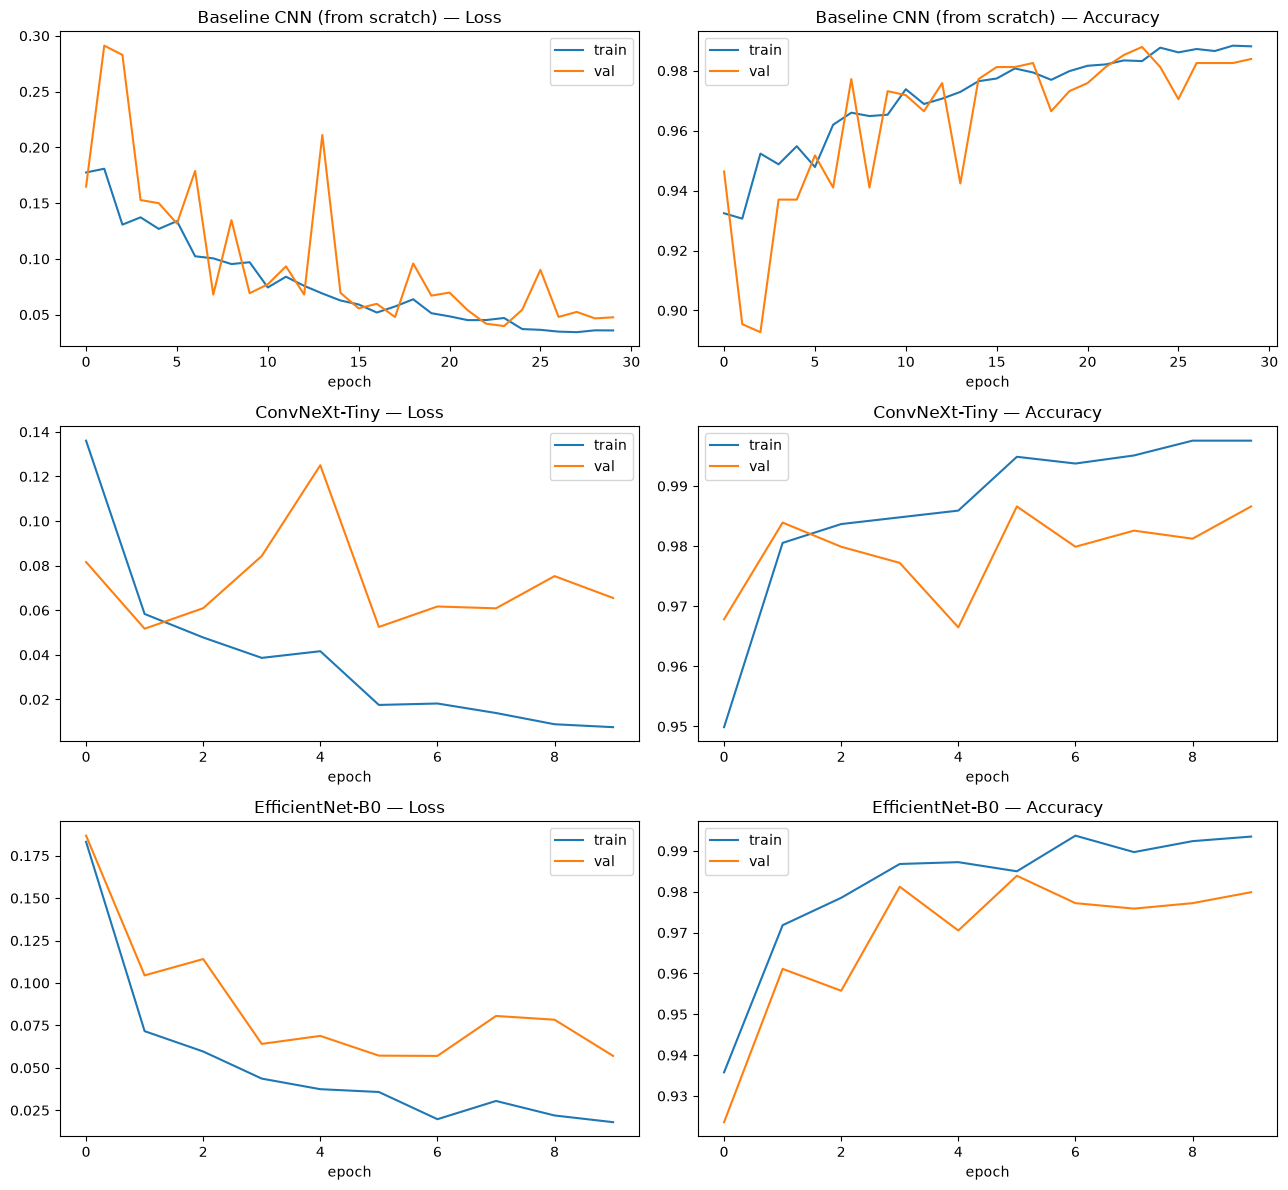

In [31]:
histories = {
    "Baseline CNN (from scratch)": baseline_history,
    "ConvNeXt-Tiny": convnext_history,
    "EfficientNet-B0": effnet_history,
}

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for row, (name, hist) in enumerate(histories.items()):
    axes[row, 0].plot(hist["train_loss"], label="train")
    axes[row, 0].plot(hist["val_loss"], label="val")
    axes[row, 0].set_title(f"{name} — Loss")
    axes[row, 0].set_xlabel("epoch"); axes[row, 0].legend()

    axes[row, 1].plot(hist["train_acc"], label="train")
    axes[row, 1].plot(hist["val_acc"], label="val")
    axes[row, 1].set_title(f"{name} — Accuracy")
    axes[row, 1].set_xlabel("epoch"); axes[row, 1].legend()

plt.tight_layout()
plt.show()

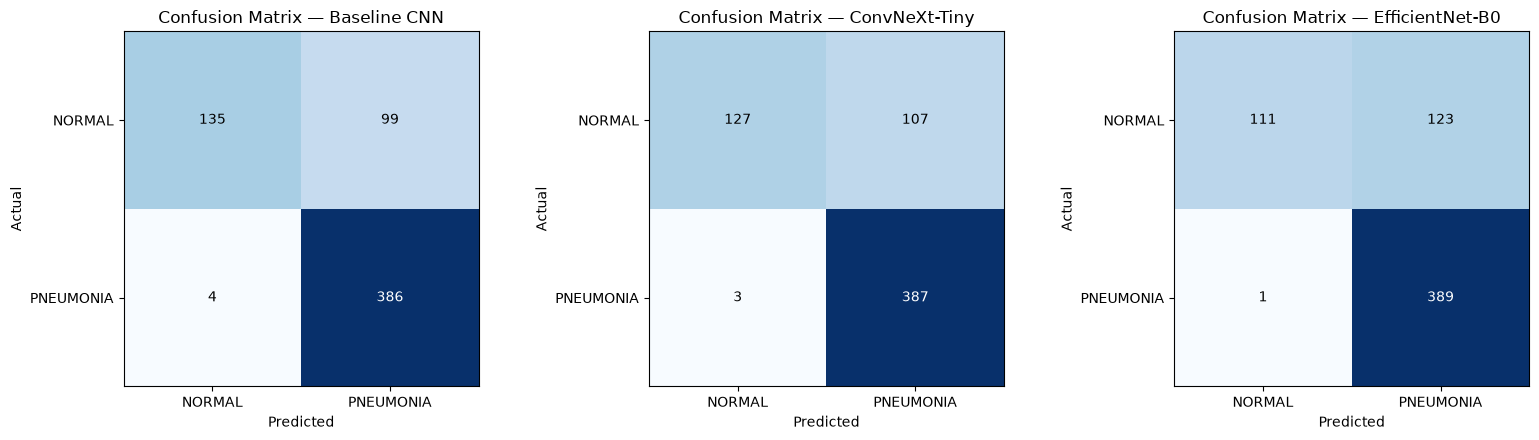

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, name in zip(axes, ["Baseline CNN", "ConvNeXt-Tiny", "EfficientNet-B0"]):
    cm = confusion_matrix(test_labels, test_preds[name])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["NORMAL", "PNEUMONIA"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["NORMAL", "PNEUMONIA"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

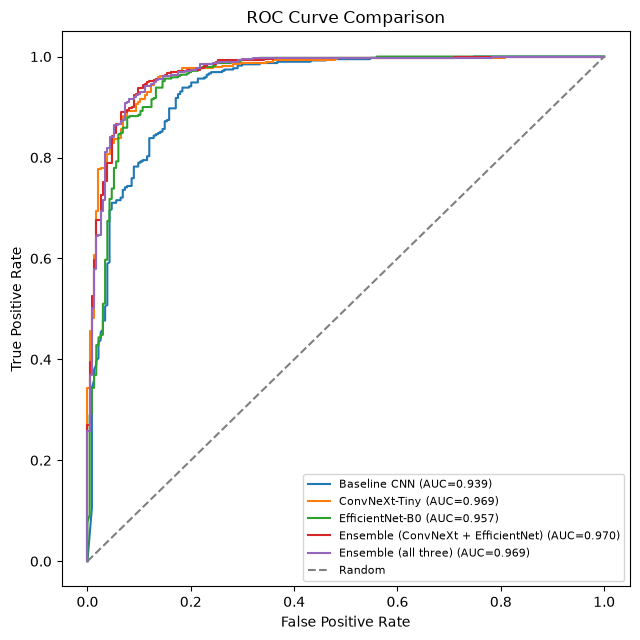

In [33]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))

for name, probs in test_probs.items():
    fpr, tpr, _ = roc_curve(test_labels, probs)
    auc = roc_auc_score(test_labels, probs)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [34]:
comparison_df = pd.DataFrame(test_metrics).T
comparison_df["threshold"] = pd.Series(thresholds)
comparison_df["trainable_params"] = [
    n_params_baseline,
    n_params_convnext,
    n_params_effnet,
    n_params_convnext + n_params_effnet,
    n_params_baseline + n_params_convnext + n_params_effnet,
]
comparison_df.round(4)

,accuracy,precision,recall,specificity,f1,roc_auc,threshold,trainable_params
Baseline CNN,0.8349,0.7959,0.9897,0.5769,0.8823,0.9389,0.7638,1206370
ConvNeXt-Tiny,0.8237,0.7834,0.9923,0.5427,0.8756,0.9686,0.4915,15570818
EfficientNet-B0,0.8013,0.7598,0.9974,0.4744,0.8625,0.9572,0.1152,1293618
Ensemble (ConvNeXt + EfficientNet),0.8189,0.7764,0.9974,0.5214,0.8732,0.9701,0.3608,16864436
Ensemble (all three),0.8285,0.7859,0.9974,0.5470,0.8791,0.9695,0.4272,18070806


In [35]:
# With only 624 test images a gap of one or two points is within noise. An exact McNemar test on the
# paired predictions asks whether a model is genuinely better than the from-scratch baseline.
rows = []
for name in ["ConvNeXt-Tiny", "EfficientNet-B0", "Ensemble (ConvNeXt + EfficientNet)"]:
    only_model, only_baseline, p_value = mcnemar(test_preds[name], test_preds["Baseline CNN"], test_labels)
    rows.append({
        "model": name,
        f"right only by {name}": only_model,
        "right only by Baseline CNN": only_baseline,
        "mcnemar_p": round(p_value, 4),
    })
pd.DataFrame(rows).set_index("model")

,right only by ConvNeXt-Tiny,right only by Baseline CNN,mcnemar_p,right only by EfficientNet-B0,right only by Ensemble (ConvNeXt + EfficientNet)
model,,,,,
ConvNeXt-Tiny,19.0,26,0.3713,NaN,NaN
EfficientNet-B0,NaN,35,0.0038,14.0,NaN
Ensemble (ConvNeXt + EfficientNet),NaN,25,0.1539,NaN,15.0


## 11. Discussion — how do the results vary?

Use the comparison table in Section 10, the ROC curves and the training curves to answer:

- **From scratch vs. pretrained:** does either transfer-learning arm beat the baseline CNN on accuracy,
  F1 and ROC-AUC, and by how much? Check the McNemar column — with 624 test images a small gap is noise.
  If the baseline is close in accuracy, look at ROC-AUC and at NORMAL-class recall before calling it a tie.
- **What the gap costs:** compare trainable parameters and epochs. EfficientNet-B0 trains roughly a tenth of
  ConvNeXt's parameters; the baseline CNN has less than the tenth of the compute that pretraining bought.
- **Ensembles:** does averaging beat the best single model, or just land between them? The disagreement table
  gives the reason — averaging only cancels errors when the members make *different* ones. Report the
  disagreement rate and kappa for each pair, and say whether the baseline CNN adds diversity or nothing.
- **Generalisation gap:** compare train and validation accuracy in the curves. Note that training accuracy is
  measured on class-balanced batches while validation uses the natural distribution, so the two lines are not
  on identical scales; a persistent gap that widens with epochs indicates overfitting.
- **Validation vs. test:** test accuracy is usually lower than validation accuracy because the official
  Kermany test folder differs from its training folder — mainly more NORMAL films being flagged as pneumonia.
  Compare NORMAL recall (specificity) with PNEUMONIA recall in the classification reports, and check whether
  the patient-level split already reduced the gap versus an image-level split.
- **PNEUMONIA recall (the clinically important class):** missed pneumonias cost more than false alarms, so
  report PNEUMONIA recall and the confusion matrices, not just overall accuracy, and state the threshold each
  model was evaluated at.
- **Parameter efficiency:** EfficientNet-B0 fine-tunes ~1.3M parameters and the baseline CNN has ~1.2M of its
  own; compare their results to see what pretraining is doing with similar capacity.

**Limitations to mention:** single-hospital paediatric data, an image-level label with a patient-level split,
a threshold tuned on only ~780 validation images, and a research exercise rather than a diagnostic tool.

## 12. (Optional) Fine-tuning more of the network

For a further comparison point, you can unfreeze one more stage of ConvNeXt-Tiny (`features[4:]` instead of
`features[6:]`) and train again at a smaller learning rate. Remove the leading `# ` to run it; it takes a while.

In [ ]:
# Optional: unfreeze stage 3 as well and fine-tune at a lower learning rate
# convnext_model.unfreeze_from = 4
# for i, block in enumerate(convnext_model.features):
#     for p in block.parameters():
#         p.requires_grad = i >= convnext_model.unfreeze_from
#
# convnext_model_ft, convnext_ft_history = train_model(
#     convnext_model, train_loader, val_loader, epochs=5, lr=5e-5, label="ConvNeXt-Tiny-Finetuned"
# )
# convnext_ft_metrics, *_ = report_metrics(
#     "ConvNeXt-Tiny (fine-tuned)", *probs_and_labels(convnext_model_ft, test_loader), thresholds["ConvNeXt-Tiny"]
# )